# 01 — Data Engineering

Notebook นี้ใช้สำหรับตรวจสอบและเตรียมข้อมูลขั้นพื้นฐาน แล้วแบ่งข้อมูลเป็น **train 70% / validation 15% / test 15%** แบบ stratified ตาม target `stroke`

> หลักสำคัญ: หลังแบ่งข้อมูลแล้ว การตัดสินใจที่เรียนรู้จากข้อมูล เช่น imputation, scaling, encoding และ outlier treatment ต้อง fit ด้วย train เท่านั้น เพื่อป้องกัน data leakage

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TARGET = "stroke"

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Load data

อ่านไฟล์ CSV จาก `data/raw/` โดยไม่แก้ไขไฟล์ต้นฉบับ

In [8]:
csv_files = sorted(RAW_DIR.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(
        f"No CSV file found in {RAW_DIR}. Run src/data/download_data.py first."
    )

RAW_FILE = csv_files[0]
df = pd.read_csv(RAW_FILE)
print(f"Loaded: {RAW_FILE.name}")
print(f"Shape: {df.shape}")
df.head()

Loaded: healthcare-dataset-stroke-data.csv
Shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 2. Data inspection

ตรวจ schema, ชนิดข้อมูล, cardinality, target distribution และข้อมูลซ้ำ ก่อนเปลี่ยนแปลงข้อมูล

In [9]:
display(df.sample(min(5, len(df)), random_state=RANDOM_STATE))
df.info()
display(df.describe(include="all").T)

inspection = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100).round(2),
    "unique_count": df.nunique(dropna=False),
})
display(inspection)
print("Exact duplicate rows:", df.duplicated().sum())

if TARGET not in df.columns:
    raise KeyError(f"Expected target column '{TARGET}' was not found.")
display(df[TARGET].value_counts(dropna=False).to_frame("count"))
display(df[TARGET].value_counts(normalize=True, dropna=False).mul(100).round(2).to_frame("percent"))

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
4688,40041,Male,31.0,0,0,No,Self-employed,Rural,64.85,23.0,Unknown,0
4478,55244,Male,40.0,0,0,Yes,Self-employed,Rural,65.29,28.3,never smoked,0
3849,70992,Female,8.0,0,0,No,children,Urban,74.42,22.5,Unknown,0
4355,38207,Female,79.0,1,0,Yes,Self-employed,Rural,76.64,19.5,never smoked,0
3826,8541,Female,75.0,0,0,Yes,Govt_job,Rural,94.77,27.2,never smoked,0


<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,5110.0,NaN,NaN,NaN,36517.829354,21161.721625,67.0,17741.25,36932.0,54682.0,72940.0
gender,5110,3,Female,2994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5110.0,NaN,NaN,NaN,43.226614,22.612647,0.08,25.0,45.0,61.0,82.0
hypertension,5110.0,NaN,NaN,NaN,0.097456,0.296607,0.0,0.0,0.0,0.0,1.0
heart_disease,5110.0,NaN,NaN,NaN,0.054012,0.226063,0.0,0.0,0.0,0.0,1.0
ever_married,5110,2,Yes,3353,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_type,5110,5,Private,2925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Residence_type,5110,2,Urban,2596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_glucose_level,5110.0,NaN,NaN,NaN,106.147677,45.28356,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,NaN,NaN,NaN,28.893237,7.854067,10.3,23.5,28.1,33.1,97.6


,dtype,missing_count,missing_percent,unique_count
id,int64,0,0.00,5110
gender,str,0,0.00,3
age,float64,0,0.00,104
hypertension,int64,0,0.00,2
heart_disease,int64,0,0.00,2
ever_married,str,0,0.00,2
work_type,str,0,0.00,5
Residence_type,str,0,0.00,2
avg_glucose_level,float64,0,0.00,3979
bmi,float64,201,3.93,419


Exact duplicate rows: 0


,count
stroke,
0,4861
1,249


,percent
stroke,
0,95.13
1,4.87


## 3. Basic data cleaning

ขั้นตอนนี้ทำเฉพาะกฎที่ไม่ต้องเรียนรู้ค่าจากทั้ง dataset ได้แก่ ทำชื่อคอลัมน์ให้สม่ำเสมอ, ตัดช่องว่างในข้อความ, ลบแถวซ้ำแบบตรงกันทุกคอลัมน์ และเปลี่ยนค่าตัวเลขที่เป็นไปไม่ได้ให้เป็น missing

ยังไม่ impute, scale, encode หรือทิ้ง outlier เพราะขั้นตอนเหล่านั้นต้อง fit จาก train หลัง split

In [10]:
clean_df = df.copy()
clean_df.columns = (
    clean_df.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)
)

text_columns = clean_df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    clean_df[column] = clean_df[column].astype("string").str.strip()

rows_before = len(clean_df)
clean_df = clean_df.drop_duplicates().reset_index(drop=True)
print(f"Removed {rows_before - len(clean_df)} exact duplicate rows.")

# Domain-validity checks: mark impossible values as missing; do not impute yet.
valid_ranges = {
    "age": (0, 120),
    "avg_glucose_level": (0, None),
    "bmi": (0, 100),
}
for column, (lower, upper) in valid_ranges.items():
    if column not in clean_df.columns:
        continue
    invalid = clean_df[column].lt(lower)
    if upper is not None:
        invalid |= clean_df[column].gt(upper)
    print(f"{column}: {invalid.sum()} impossible value(s) converted to NaN")
    clean_df.loc[invalid, column] = np.nan

if clean_df[TARGET].isna().any():
    raise ValueError("Target contains missing values; investigate before splitting.")

clean_df.head()

Removed 0 exact duplicate rows.
age: 0 impossible value(s) converted to NaN
avg_glucose_level: 0 impossible value(s) converted to NaN
bmi: 0 impossible value(s) converted to NaN


,id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 4. Train / validation / test split

ใช้ stratification เพื่อรักษาสัดส่วนผู้ป่วย stroke ในทุก split ซึ่งสำคัญเพราะ target ไม่สมดุล

- Train: 70% — fit preprocessing และ model
- Validation: 15% — เปรียบเทียบตัวเลือกสุดท้ายหรือกำหนด threshold
- Test: 15% — ประเมินผลครั้งสุดท้ายเพียงครั้งเดียว

In [11]:
train_df, holdout_df = train_test_split(
    clean_df,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=clean_df[TARGET],
)
validation_df, test_df = train_test_split(
    holdout_df,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=holdout_df[TARGET],
)

train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

split_summary = pd.DataFrame({
    "rows": [len(train_df), len(validation_df), len(test_df)],
    "percent": [len(train_df), len(validation_df), len(test_df)],
    "stroke_rate": [train_df[TARGET].mean(), validation_df[TARGET].mean(), test_df[TARGET].mean()],
}, index=["train", "validation", "test"])
split_summary["percent"] = split_summary["percent"].div(len(clean_df)).mul(100).round(2)
split_summary["stroke_rate"] = split_summary["stroke_rate"].mul(100).round(2)
display(split_summary)

,rows,percent,stroke_rate
train,3577,70.00,4.86
validation,766,14.99,4.83
test,767,15.01,4.95


## 5. Missing-data analysis

สำรวจรูปแบบ missing โดยใช้ train เป็นหลัก ห้ามใช้ค่า median/mode จาก validation หรือ test ไปเติม train

,missing_count,missing_percent
bmi,148,4.14


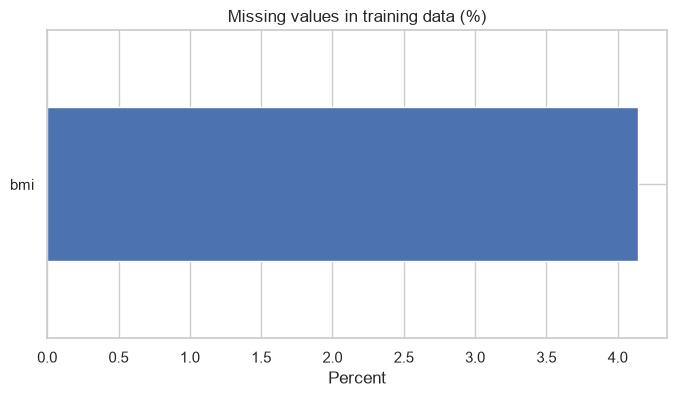

In [12]:
def missing_summary(frame: pd.DataFrame) -> pd.DataFrame:
    result = pd.DataFrame({
        "missing_count": frame.isna().sum(),
        "missing_percent": frame.isna().mean().mul(100).round(2),
    })
    return result[result["missing_count"] > 0].sort_values("missing_percent", ascending=False)

display(missing_summary(train_df))

missing_summary(train_df)["missing_percent"].sort_values().plot(
    kind="barh", figsize=(8, 4), title="Missing values in training data (%)"
)
plt.xlabel("Percent")
plt.show()

## 6. Outlier detection

IQR ใช้เป็นเครื่องมือ flag ค่า extreme บน train ไม่ใช่กฎให้ลบทันที ในข้อมูลทางการแพทย์ค่าที่สูงอาจเป็นสัญญาณสำคัญและไม่ใช่ข้อมูลผิด

In [13]:
def iqr_outlier_summary(frame: pd.DataFrame, exclude=(TARGET, "id")) -> pd.DataFrame:
    rows = []
    numeric_columns = frame.select_dtypes(include=np.number).columns.difference(exclude)
    for column in numeric_columns:
        series = frame[column].dropna()
        q1, q3 = series.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (series < lower) | (series > upper)
        rows.append({
            "feature": column,
            "lower_bound": lower,
            "upper_bound": upper,
            "outlier_count": int(mask.sum()),
            "outlier_percent": round(mask.mean() * 100, 2),
        })
    return pd.DataFrame(rows).sort_values("outlier_percent", ascending=False)

outlier_summary = iqr_outlier_summary(train_df)
display(outlier_summary)

,feature,lower_bound,upper_bound,outlier_count,outlier_percent
1,avg_glucose_level,23.205,167.885,436,12.19
4,hypertension,0.000,0.000,344,9.62
3,heart_disease,0.000,0.000,193,5.40
2,bmi,9.100,47.500,79,2.30
0,age,-26.500,113.500,0,0.00


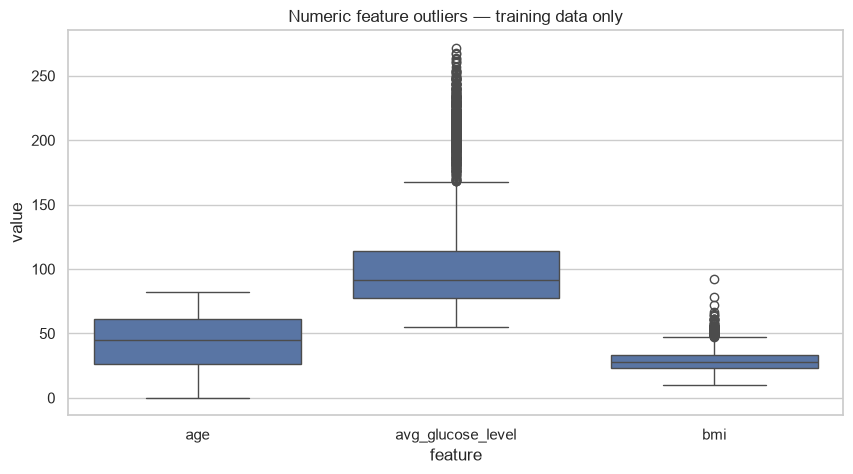

In [14]:
numeric_plot_columns = [
    column for column in ["age", "avg_glucose_level", "bmi"]
    if column in train_df.columns
]
if numeric_plot_columns:
    melted = train_df[numeric_plot_columns].melt(var_name="feature", value_name="value")
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=melted, x="feature", y="value")
    plt.title("Numeric feature outliers — training data only")
    plt.show()

## 7. Exploratory Data Analysis (EDA)

EDA หลัง split ต้องใช้ train เท่านั้น เพื่อไม่ให้ลักษณะของ validation/test มีผลต่อการออกแบบ feature หรือ model

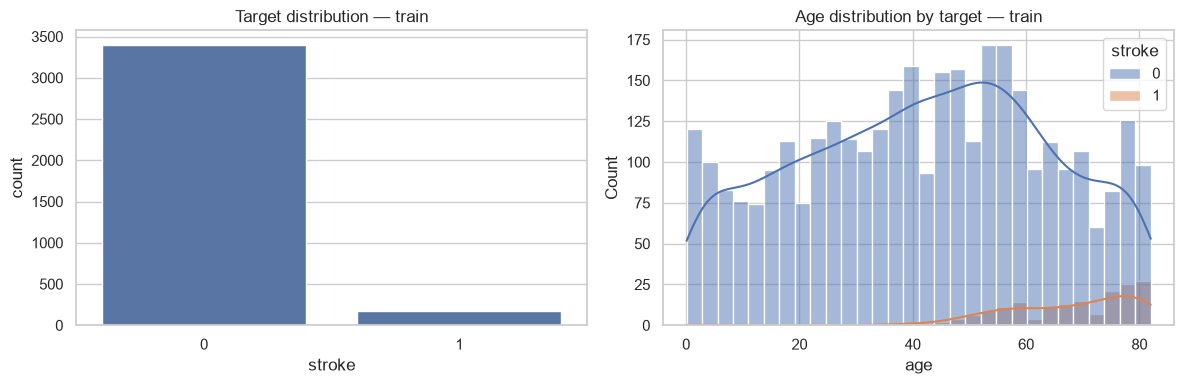

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=train_df, x=TARGET, ax=axes[0])
axes[0].set_title("Target distribution — train")

if "age" in train_df.columns:
    sns.histplot(data=train_df, x="age", hue=TARGET, bins=30, kde=True, ax=axes[1])
    axes[1].set_title("Age distribution by target — train")
plt.tight_layout()
plt.show()

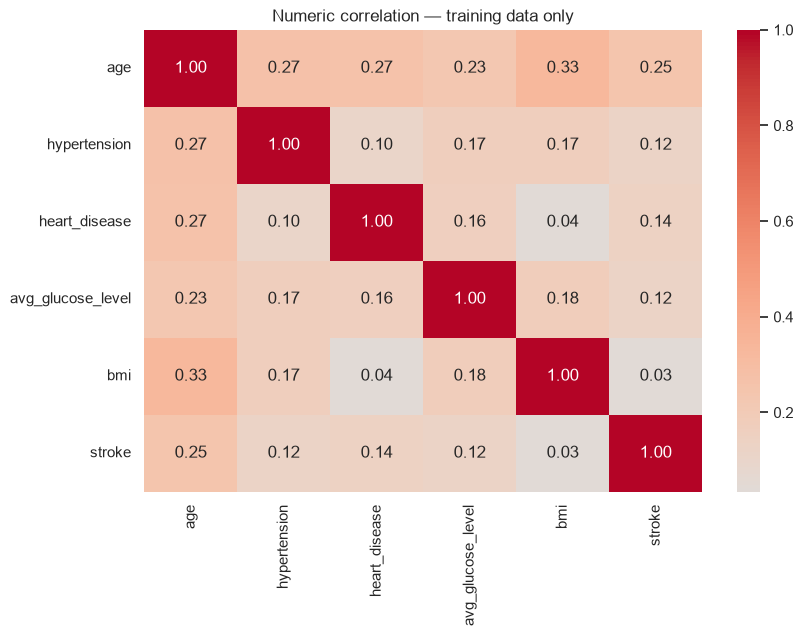

stroke,0,1
gender,,
Female,0.951,0.049
Male,0.952,0.048
Other,1.000,0.000


stroke,0,1
ever_married,,
No,0.985,0.015
Yes,0.934,0.066


stroke,0,1
work_type,,
Govt_job,0.947,0.053
Never_worked,1.000,0.000
Private,0.951,0.049
Self-employed,0.917,0.083
children,0.998,0.002


stroke,0,1
residence_type,,
Rural,0.953,0.047
Urban,0.950,0.050


stroke,0,1
smoking_status,,
Unknown,0.969,0.031
formerly smoked,0.924,0.076
never smoked,0.954,0.046
smokes,0.942,0.058


In [16]:
numeric_train = train_df.select_dtypes(include=np.number).drop(columns=["id"], errors="ignore")
if numeric_train.shape[1] > 1:
    plt.figure(figsize=(9, 6))
    sns.heatmap(numeric_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Numeric correlation — training data only")
    plt.show()

categorical_columns = train_df.select_dtypes(include=["object", "string", "category"]).columns
for column in categorical_columns:
    display(pd.crosstab(train_df[column], train_df[TARGET], normalize="index").round(3))

## 8. Save splits

บันทึกข้อมูลที่ยังไม่ได้ impute/scale/encode เพื่อให้ขั้นตอน model development นำ preprocessing ใส่ใน scikit-learn Pipeline และ fit เฉพาะ train หรือแต่ละ cross-validation fold

In [17]:
output_files = {
    "train": PROCESSED_DIR / "train.csv",
    "validation": PROCESSED_DIR / "validation.csv",
    "test": PROCESSED_DIR / "test.csv",
}

train_df.to_csv(output_files["train"], index=False)
validation_df.to_csv(output_files["validation"], index=False)
test_df.to_csv(output_files["test"], index=False)

for split_name, path in output_files.items():
    print(f"Saved {split_name:10s} -> {path}")

Saved train      -> c:\Users\Acer\Desktop\Study\KU\ML\stroke-prediction\data\processed\train.csv
Saved validation -> c:\Users\Acer\Desktop\Study\KU\ML\stroke-prediction\data\processed\validation.csv
Saved test       -> c:\Users\Acer\Desktop\Study\KU\ML\stroke-prediction\data\processed\test.csv
